In [1]:
import logging
import os

import numpy as np
import pandas as pd
import pyarrow as pa
from pyarrow import orc
from collections import Counter
import pickle

In [2]:
################### Environment
prefix_origin_2021_loc = '/Users/raps/datasets/2021-03-23-popular-3k-python-orc/origin_visit_status/'
prefix_origin_2023_loc = '/Users/raps/datasets/2023-09-06-popular-1k-orc/origin_visit_status/'
prefix_origin_2021_dist = '/home/infres/rapaport/datasets/2021-03-23-popular-3k-python-orc/origin_visit_status/'
prefix_origin_2023_dist = '/home/infres/rapaport/datasets/2023-09-06-popular-1k/origin_visit_status/'
prefix_origin_all_dist = '/home/infres/rapaport/datasets/2023-09-06/origin_visit_status/'

prefix_snapshot_2021_loc = '/Users/raps/datasets/2021-03-23-popular-3k-python-orc/snapshot_branch/'
prefix_snapshot_2023_loc = '/Users/raps/datasets/2023-09-06-popular-1k-orc/snapshot_branch/'
prefix_snapshot_2021_dist = '/home/infres/rapaport/datasets/2021-03-23-popular-3k-python-orc/snapshot_branch/'
prefix_snapshot_2023_dist = '/home/infres/rapaport/datasets/2023-09-06-popular-1k/snapshot_branch/'
prefix_snapshot_all_dist = '/home/infres/rapaport/datasets/2023-09-06/snapshot_branch/'

prefix_revision_2021_dist = '/home/infres/rapaport/datasets/2021-03-23-popular-3k-python-orc/revision/'

EMPTY_SNAPSHOT = '1a8893e6a86f444e8be8e7bda6cb34fb1735a00e'

In [ ]:
db = {}
orc_file_list = os.listdir(prefix_revision_2021_dist)
for orc_file in orc_file_list:
    table = orc.read_table(prefix_revision_2021_dist + orc_file)
    list_origin_visit_status = table[0]
    for i in range(len(list_origin_visit_status)):
        current_id = table[0][i].as_py()
        current_author = table[2][i].as_py().decode('latin1')
        #print(current_author)
        current_date = table[3][i].as_py()
        #print(current_date)
        current_date_offset = table[4][i].as_py()
        #print(current_date_offset)
        current_committer = table[5][i].as_py().decode('latin1')
        #print(current_committer)
        current_cdate = table[6][i].as_py()
        #print(current_cdate)
        current_cdate_offset = table[7][i].as_py()
        #print(current_cdate_offset)
        db.setdefault(current_author, set()).add((current_id, current_date - pd.Timedelta(minutes=current_date_offset), current_date_offset))
        if current_author != current_committer:
            db.setdefault(current_committer, set()).add((current_id, current_cdate - pd.Timedelta(minutes=current_date_offset), current_cdate_offset))

pyarrow.Table
id: string
message: binary
author: binary
date: timestamp[ns]
date_offset: int16
committer: binary
committer_date: timestamp[ns]
committer_offset: int16
directory: string
----
id: [["90242c8a8b71eb4bd945d7735e9aac0ab92fc2c5","4024813f367f1bb370da126684da3cfbb1e867b8","c0550c4bf1a6b868ac98b63f88ffd1a7ebdbeaeb","50638530e61307f174950ef295235a6dbddec6b9","4034db215b92c68ce55cf1c658d4ef7599ccc45a",...,"3e15f6d64ccbb1f98ff64323a25304db662a45ba","8e3882742b5d655eefbe5b9b18971f96fdd2bea6","3edc4202b0005ea9cbdf6fac03347bd5d560887c","4e65ae17fd92b242a11d47917effeb4606b901db","4e7b4ad42da58ae4ef7f2282ab0af11fc7c1073a"]]
message: [[526576657274202255706461746520434F4E545249425554494E472E6D64220A0A54686973207265766572747320636F6D6D697420663463373035396130623332653037356163656439633537383732386635663562613831396435612E0A,4D657267652070756C6C2072657175657374202331333836392066726F6D206E6F726D616C68756D616E2F6E74685F6F726465725F646966665F6C6F6769630A0A436F72726563746C792068616E646C652064

5m 35.6s

In [4]:
with open('db.pkl', 'wb') as f:
    pickle.dump(db, f)

In [5]:
db2 = {}
with open('db.pkl', 'rb') as f:
    db2 = pickle.load(f)

32.0s

In [6]:
for aut in db2:
    db2[aut] = sorted(db2[aut], key=lambda val: val[1])

In [7]:
author_flag = {}
for author in db2:
    id1, ts1, tz1 = None, None, None
    for (id, ts, tz) in db2[author]:
        if ts1 == None:
            id1, ts1, tz1 = id, ts, tz
            continue
        if tz1 != tz:
            for hour in range(24,0,-1): 
                if ts - ts1 < pd.Timedelta(hours=hour):
                    author_flag.setdefault(hour, {}).setdefault(author, set()).add(("swh:1:rev:"+id1, "swh:1:rev:"+id))
        id1, ts1, tz1 = id, ts, tz

1m 23.5s

In [8]:
for hour in range(24,0,-1):
    print("for a difference of ",hour," hour(s) | amount of author in the timestamp heuristic: ",len(author_flag[hour]))
    print("for a difference of ",hour," hour(s) | amount of flag in the timestamp heuristic: ",len([x for author in author_flag[hour] for x in author]))

for a difference of  24  hour(s) | amount of author in the timestamp heuristic:  6334
for a difference of  24  hour(s) | amount of flag in the timestamp heuristic:  202688
for a difference of  23  hour(s) | amount of author in the timestamp heuristic:  6255
for a difference of  23  hour(s) | amount of flag in the timestamp heuristic:  200160
for a difference of  22  hour(s) | amount of author in the timestamp heuristic:  6152
for a difference of  22  hour(s) | amount of flag in the timestamp heuristic:  196864
for a difference of  21  hour(s) | amount of author in the timestamp heuristic:  6059
for a difference of  21  hour(s) | amount of flag in the timestamp heuristic:  193888
for a difference of  20  hour(s) | amount of author in the timestamp heuristic:  5961
for a difference of  20  hour(s) | amount of flag in the timestamp heuristic:  190752
for a difference of  19  hour(s) | amount of author in the timestamp heuristic:  5863
for a difference of  19  hour(s) | amount of flag in t

In [9]:
import matplotlib.pyplot as plt


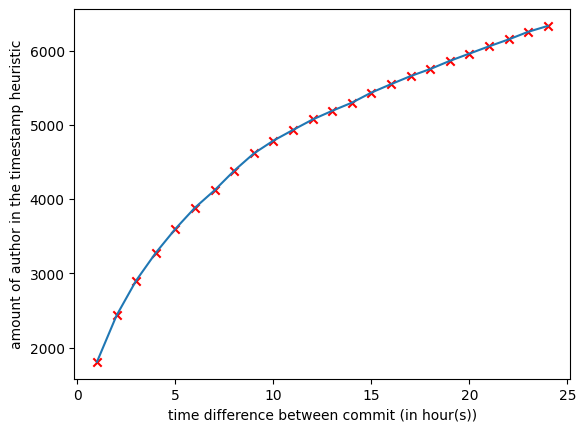

In [13]:
# amount of author per hour diff
x = [hour for hour in range(24,0,-1)]
y = [len(author_flag[hour]) for hour in range(24,0,-1)]
plt.plot(x,y)
plt.scatter(x, y, color='red', marker='x')
plt.xlabel('time difference between commit (in hour(s))')
plt.ylabel('amount of author in the timestamp heuristic')
plt.show()

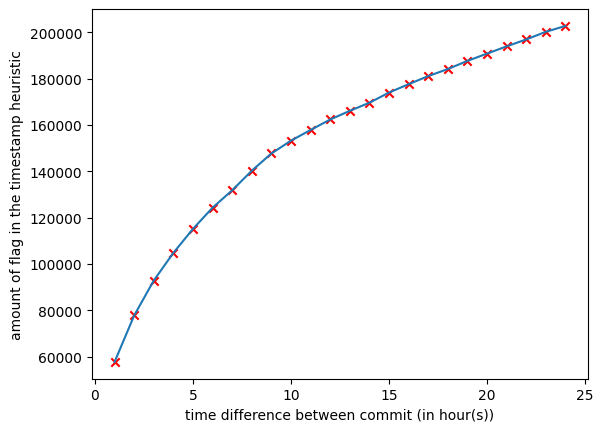

In [15]:
# amount of flag per hour diff
x = [hour for hour in range(24,0,-1)]
y = [len([x for author in author_flag[hour] for x in author]) for hour in range(24,0,-1)]
plt.plot(x,y)
plt.scatter(x, y, color='red', marker='x')
plt.xlabel('time difference between commit (in hour(s))')
plt.ylabel('amount of flag in the timestamp heuristic')
plt.show()

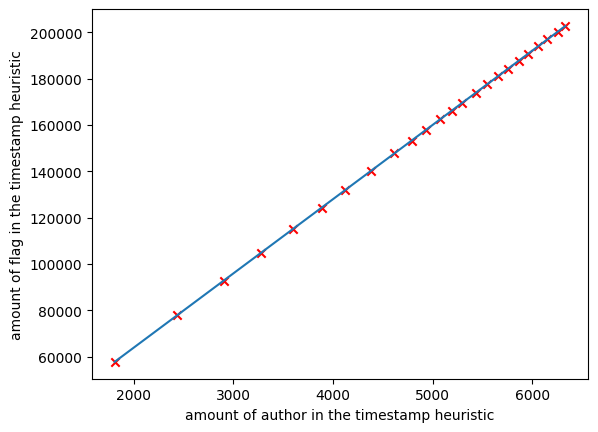

In [16]:
# amount of flag per hour diff
x = [len(author_flag[hour]) for hour in range(24,0,-1)]
y = [len([x for author in author_flag[hour] for x in author]) for hour in range(24,0,-1)]
plt.plot(x,y)
plt.scatter(x, y, color='red', marker='x')
plt.xlabel('amount of author in the timestamp heuristic')
plt.ylabel('amount of flag in the timestamp heuristic')
plt.show()